### Overview

This notebook examines the correlation between probe task choices and odor pleasantness ratings. Specifically, it addresses:

- **Changes** in both choice behavior and odor ratings from pre- to post-meal  
- **Correlations** assessed **separately at pre-meal and post-meal** timepoints  
- Analysis is based on processed probe choice data: `'probe_choice_behavior_all.csv'` generated by the notebook: `analyze_probe.ipynb`

Reminders:
- two subjects excluded based on odor prediction task (`chance_subjects`)
- also `sub-36` was excluded from the analysis due to missing odor rating data


In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon
from scipy.stats import pearsonr

In [2]:
# load common plot configurations
from plot_config import session_colors

In [6]:
# two subjects excluded based on odor prediction task
chance_subjects = ['sub-19', 'sub-33']

In [31]:
# Base directory
base_path = Path('/Users/liuq13/project-SPCD/beh_processed_subs')
file_path = base_path / 'probe_choice_behavior_all.csv' # load this preprocessed file from "analyze_probe" code

# Load the CSV
pivoted = pd.read_csv(file_path)
pivoted

,subject,choice_class,post,pre,change
0,sub-01,A1>C,0.166667,0.083333,0.083333
1,sub-01,A2>A1,0.000000,0.916667,-0.916667
2,sub-01,A2>C,0.000000,0.083333,-0.083333
3,sub-01,B1>D,0.000000,0.000000,0.000000
4,sub-01,B2>B1,0.000000,0.727273,-0.727273
...,...,...,...,...,...
187,sub-41,A2>A1,0.200000,0.272727,-0.072727
188,sub-41,A2>C,0.090909,0.000000,0.090909
189,sub-41,B1>D,0.090909,0.090909,0.000000
190,sub-41,B2>B1,0.100000,0.181818,-0.081818


### Correlation Between Odor Rating Change and Choice Behavior Change

This analysis examines whether the change in **subjective odor pleasantness ratings** is associated with the change in **behavioral choices** before and after the meal.

For each probe trial type (e.g., A1 > A2), we identified the two associated odors and computed the **relative change in pleasantness ratings** (Δrating = Δ(O_left - O_right)). This value was then correlated with the **change in choice preference** for the corresponding cue pair (e.g., increase in choosing A1 over A2).

**Subject sub-36** was excluded from the analysis due to missing odor rating data.

In [32]:
# read in odor rating change data

all_dfs = []

# Loop through each subject folder
for sub_path in sorted(base_path.iterdir()):
    if sub_path.is_dir():
        sub_id = sub_path.name

        if sub_id in chance_subjects:
            continue  # skip subjects performing at chance level
        
        file_path = sub_path / 'pleasantness_summary.csv'
        if file_path.exists():
            df = pd.read_csv(file_path)
            df['subject'] = sub_id
            all_dfs.append(df)

# Combine all subject data
rating_change_df = pd.concat(all_dfs, ignore_index=True)

# reorder columns
rating_change_df = rating_change_df[['subject', 'odor_num', 'pre_mean', 'post_mean', 'change']]
rating_change_df

,subject,odor_num,pre_mean,post_mean,change
0,sub-01,0,0.750,0.750,0.000
1,sub-01,1,1.750,2.375,0.625
2,sub-01,2,2.250,1.000,-1.250
3,sub-02,0,0.000,0.000,0.000
4,sub-02,1,-1.000,-1.375,-0.375
...,...,...,...,...,...
88,sub-40,1,1.000,2.125,1.125
89,sub-40,2,3.500,2.625,-0.875
90,sub-41,0,1.375,2.875,1.500
91,sub-41,1,1.000,-0.500,-1.500


### create mapping between odor_num and cue types

In [17]:
cue_to_odor = {
    'A1': 1, 'A2': 2, 'C': 0,
    'B1': 1, 'B2': 2, 'D': 0
}

# Split 'A1>A2' → 'A1', 'A2'
pivoted[['left_cue', 'right_cue']] = pivoted['choice_class'].str.split('>', expand=True)

# Map to odor numbers
pivoted['left_odor'] = pivoted['left_cue'].map(cue_to_odor)
pivoted['right_odor'] = pivoted['right_cue'].map(cue_to_odor)

pivoted.head(6)

,subject,choice_class,post,pre,change,left_cue,right_cue,left_odor,right_odor
0,sub-01,A1>C,0.166667,0.083333,0.083333,A1,C,1,0
1,sub-01,A2>A1,0.000000,0.916667,-0.916667,A2,A1,2,1
2,sub-01,A2>C,0.000000,0.083333,-0.083333,A2,C,2,0
3,sub-01,B1>D,0.000000,0.000000,0.000000,B1,D,1,0
4,sub-01,B2>B1,0.000000,0.727273,-0.727273,B2,B1,2,1
5,sub-01,B2>D,0.000000,0.000000,0.000000,B2,D,2,0


In [18]:
rating_change_df = rating_change_df.rename(columns={'change': 'odor_rating_change'})

# Merge for left odor
merged = pivoted.merge(
    rating_change_df[['subject', 'odor_num', 'odor_rating_change']],
    left_on=['subject', 'left_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).rename(columns={'odor_rating_change': 'left_rating_change'}).drop(columns='odor_num')

# Merge for right odor
merged = merged.merge(
    rating_change_df[['subject', 'odor_num', 'odor_rating_change']],
    left_on=['subject', 'right_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).rename(columns={'odor_rating_change': 'right_rating_change'}).drop(columns='odor_num')

merged['rating_diff'] = merged['left_rating_change'] - merged['right_rating_change']
merged

,subject,choice_class,post,pre,change,left_cue,right_cue,left_odor,right_odor,left_rating_change,right_rating_change,rating_diff
0,sub-01,A1>C,0.166667,0.083333,0.083333,A1,C,1,0,0.625,0.000,0.625
1,sub-01,A2>A1,0.000000,0.916667,-0.916667,A2,A1,2,1,-1.250,0.625,-1.875
2,sub-01,A2>C,0.000000,0.083333,-0.083333,A2,C,2,0,-1.250,0.000,-1.250
3,sub-01,B1>D,0.000000,0.000000,0.000000,B1,D,1,0,0.625,0.000,0.625
4,sub-01,B2>B1,0.000000,0.727273,-0.727273,B2,B1,2,1,-1.250,0.625,-1.875


In [20]:
# Drop rows with missing rating difference
merged = merged.dropna(subset=['rating_diff'])

print("Subjects included in correlation analysis:", merged['subject'].nunique())
print("Excluded subjects (likely due to missing odor rating data):", 
      set(pivoted['subject'].unique()) - set(merged['subject'].unique()))


Subjects included in correlation analysis: 31
Excluded subjects (likely due to missing odor rating data): {'sub-36'}


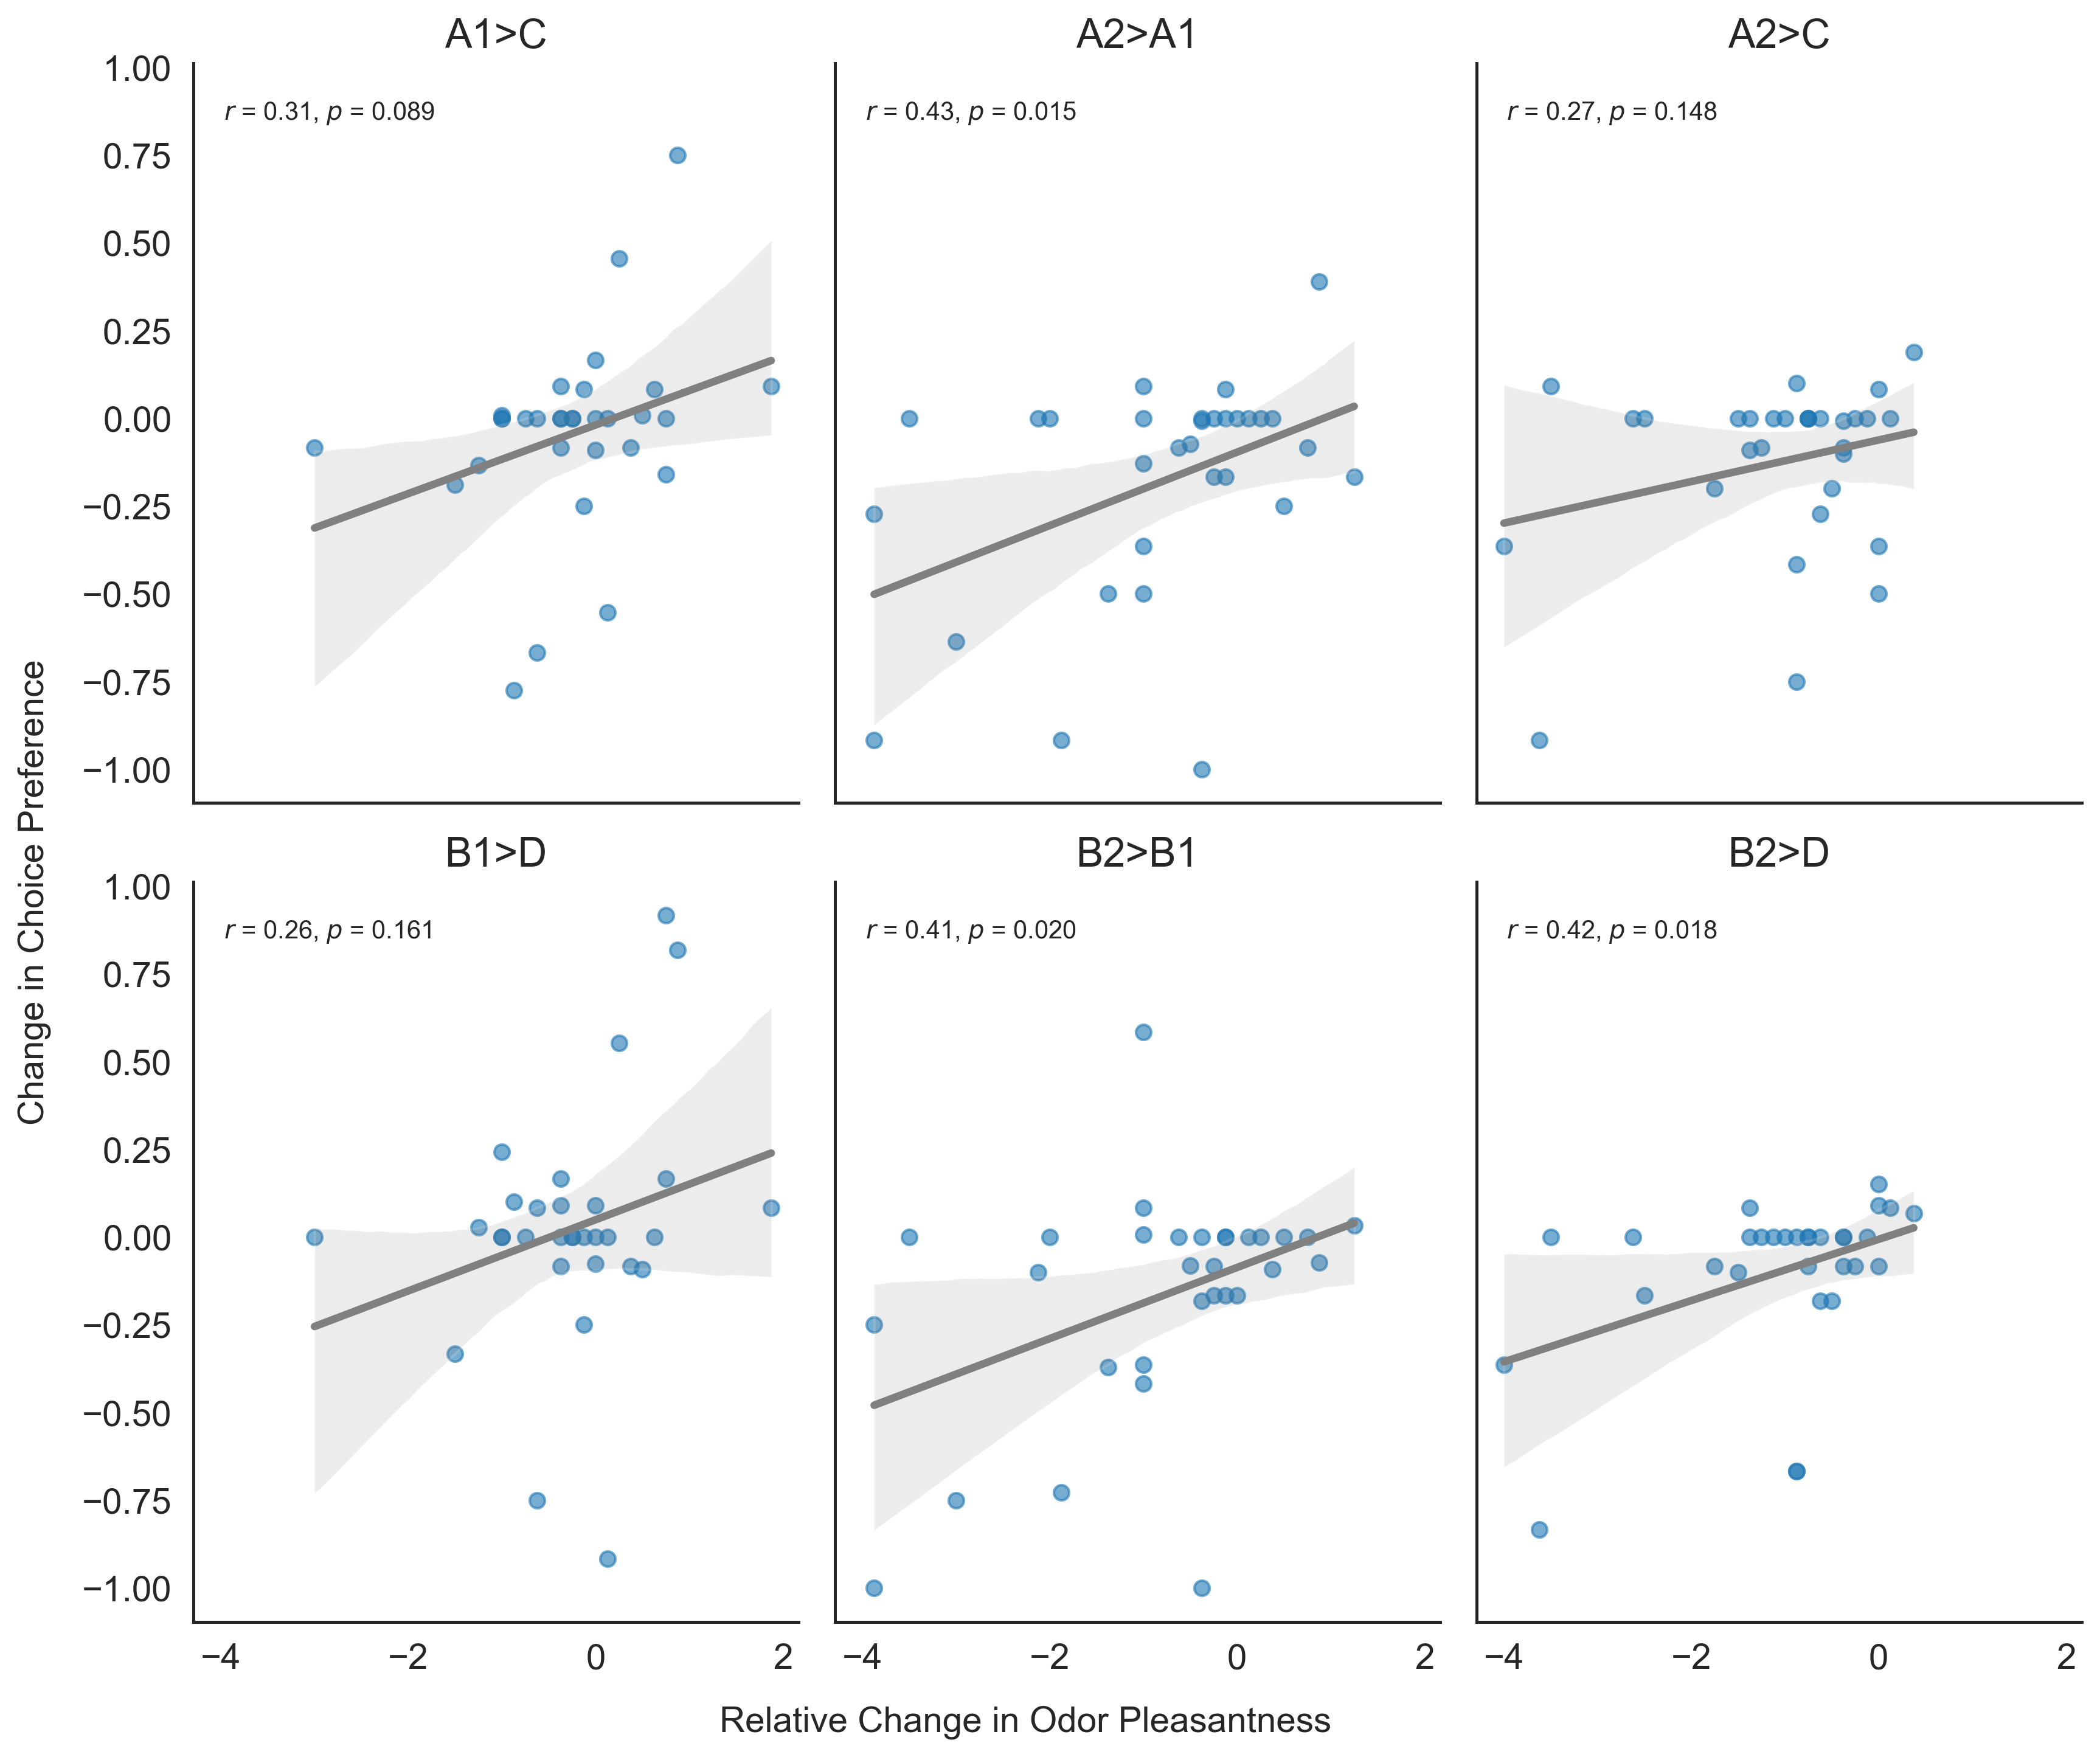

In [42]:
# First, compute the stats and store in a dict for quick access
stat_texts = {}

for name, group in merged.groupby('choice_class'):
    r, p = pearsonr(group['rating_diff'], group['change'])
    stat_texts[name] = f"$r$ = {r:.2f}, $p$ = {p:.3f}"

g = sns.lmplot(
    data=merged,
    x='rating_diff', y='change',
    col='choice_class', col_wrap=3,
    height=5,           # height of each facet in inches
    aspect=0.8,         # aspect = width/height, so 0.8 gives width of 4 inches
    scatter_kws={'alpha': 0.6}, line_kws={'color': 'gray'}
)

g.set_titles("{col_name}")

# Set labels only on the edge subplots
for ax in g.axes.flat:
    ax.set_xlabel('')
    ax.set_ylabel('')

# Add labels only to bottom-left subplot or use fig.text for figure-level labels
g.fig.text(0.5, 0.04, 'Relative Change in Odor Pleasantness', ha='center', fontsize=14)
g.fig.text(0.04, 0.5, 'Change in Choice Preference', va='center', rotation='vertical', fontsize=14)

# Add stats to each subplot
for ax, title in zip(g.axes.flat, g.col_names):
    stat = stat_texts.get(title, "")
    ax.text(0.05, 0.95, stat, transform=ax.transAxes,
            fontsize=10, verticalalignment='top')
plt.tight_layout()

plt.subplots_adjust(bottom=0.1, left=0.12)  # Make room for the labels

plt.savefig("../plots/probe_change_corr.pdf", format='pdf', bbox_inches='tight')
plt.show()


### Summary:

This analysis tested whether relative changes in odor pleasantness ratings (before vs. after meal) predicted changes in behavioral preference across different cue pairings.

Each point in the plots represents one subject's change in choice preference (Δ choice proportion) plotted against the corresponding change in relative odor pleasantness (Δ rating difference between the two odors).

**Key Findings:**

- Significant positive correlations were found for the following cue pairs:
  - **A1 > A2**: *r* = 0.39, *p* = 0.032
  - **B1 > B2**: *r* = 0.42, *p* = 0.023
  - **B2 > B3**: *r* = 0.39, *p* = 0.034

- These are the same cue pairs that showed significant **behavioral change** after the meal, suggesting a consistent link between:
  - Reduced pleasantness of the devalued odor
  - Decreased preference for cues associated with that odor

- Other comparisons (e.g., **A1 > A3**, **A2 > A3**, **B1 > B3**) showed weaker, non-significant correlations, consistent with their lack of behavioral change.

These results support the idea that meal-induced devaluation affects both **subjective value** (pleasantness ratings) and **behavioral decisions**, and that the two are meaningfully aligned.


### Correlation between odor rating and choice behavior (pre and post)

This analysis shifts focus from **changes** over time to examine whether subjective odor pleasantness ratings are associated with behavioral choices at **each timepoint**—before and after the meal.


In [24]:
# rename and re-merge for pre and post separately
rating_pre_df = rating_change_df.rename(columns={'pre_mean': 'odor_rating_pre'})[['subject', 'odor_num', 'odor_rating_pre']]
rating_post_df = rating_change_df.rename(columns={'post_mean': 'odor_rating_post'})[['subject', 'odor_num', 'odor_rating_post']]

In [25]:
# Merge left and right odor ratings for pre
merged_pre = pivoted.merge(
    rating_pre_df.rename(columns={'odor_rating_pre': 'left_rating_pre'}),
    left_on=['subject', 'left_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).drop(columns='odor_num')

merged_pre = merged_pre.merge(
    rating_pre_df.rename(columns={'odor_rating_pre': 'right_rating_pre'}),
    left_on=['subject', 'right_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).drop(columns='odor_num')

merged_pre['rating_diff_pre'] = merged_pre['left_rating_pre'] - merged_pre['right_rating_pre']

In [26]:
# Merge left and right odor ratings for post
merged_post = pivoted.merge(
    rating_post_df.rename(columns={'odor_rating_post': 'left_rating_post'}),
    left_on=['subject', 'left_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).drop(columns='odor_num')

merged_post = merged_post.merge(
    rating_post_df.rename(columns={'odor_rating_post': 'right_rating_post'}),
    left_on=['subject', 'right_odor'],
    right_on=['subject', 'odor_num'],
    how='left'
).drop(columns='odor_num')

merged_post['rating_diff_post'] = merged_post['left_rating_post'] - merged_post['right_rating_post']

In [27]:
# Drop missing data before correlation
merged_pre = merged_pre.dropna(subset=['rating_diff_pre', 'pre'])
merged_post = merged_post.dropna(subset=['rating_diff_post', 'post'])

In [28]:
# Add phase label
merged_pre['meal_phase'] = 'Pre'
merged_post['meal_phase'] = 'Post'

# Select common columns to concatenate
common_cols = ['subject', 'choice_class', 'rating_diff_pre', 'pre', 'meal_phase']
pre_df = merged_pre[common_cols].rename(columns={
    'rating_diff_pre': 'rating_diff',
    'pre': 'choice'
})

post_df = merged_post[['subject', 'choice_class', 'rating_diff_post', 'post', 'meal_phase']].rename(columns={
    'rating_diff_post': 'rating_diff',
    'post': 'choice'
})

# Concatenate
combined = pd.concat([pre_df, post_df], ignore_index=True)
combined

,subject,choice_class,rating_diff,choice,meal_phase
0,sub-01,A1>C,1.000,0.083333,Pre
1,sub-01,A2>A1,0.500,0.916667,Pre
2,sub-01,A2>C,1.500,0.083333,Pre
3,sub-01,B1>D,1.000,0.000000,Pre
4,sub-01,B2>B1,0.500,0.727273,Pre
...,...,...,...,...,...
367,sub-41,A2>A1,-1.000,0.200000,Post
368,sub-41,A2>C,-4.375,0.090909,Post
369,sub-41,B1>D,-3.375,0.090909,Post
370,sub-41,B2>B1,-1.000,0.100000,Post


In [29]:
# Compute correlation label for each group
corr_labels = (
    combined
    .dropna(subset=['rating_diff', 'choice'])
    .groupby(['choice_class', 'meal_phase'])
    .apply(lambda g: f"$r$ = {pearsonr(g['rating_diff'], g['choice'])[0]:.2f}, "
                     f"$p$ = {pearsonr(g['rating_diff'], g['choice'])[1]:.3f}")
    .reset_index()
    .rename(columns={0: 'corr_label'})
)

# Merge back to combined
combined = combined.merge(corr_labels, on=['choice_class', 'meal_phase'], how='left')


/var/folders/br/nr4k1vxj1_j7jxk17x7xr8n9g2q0k8/T/ipykernel_3190/3198286800.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  combined


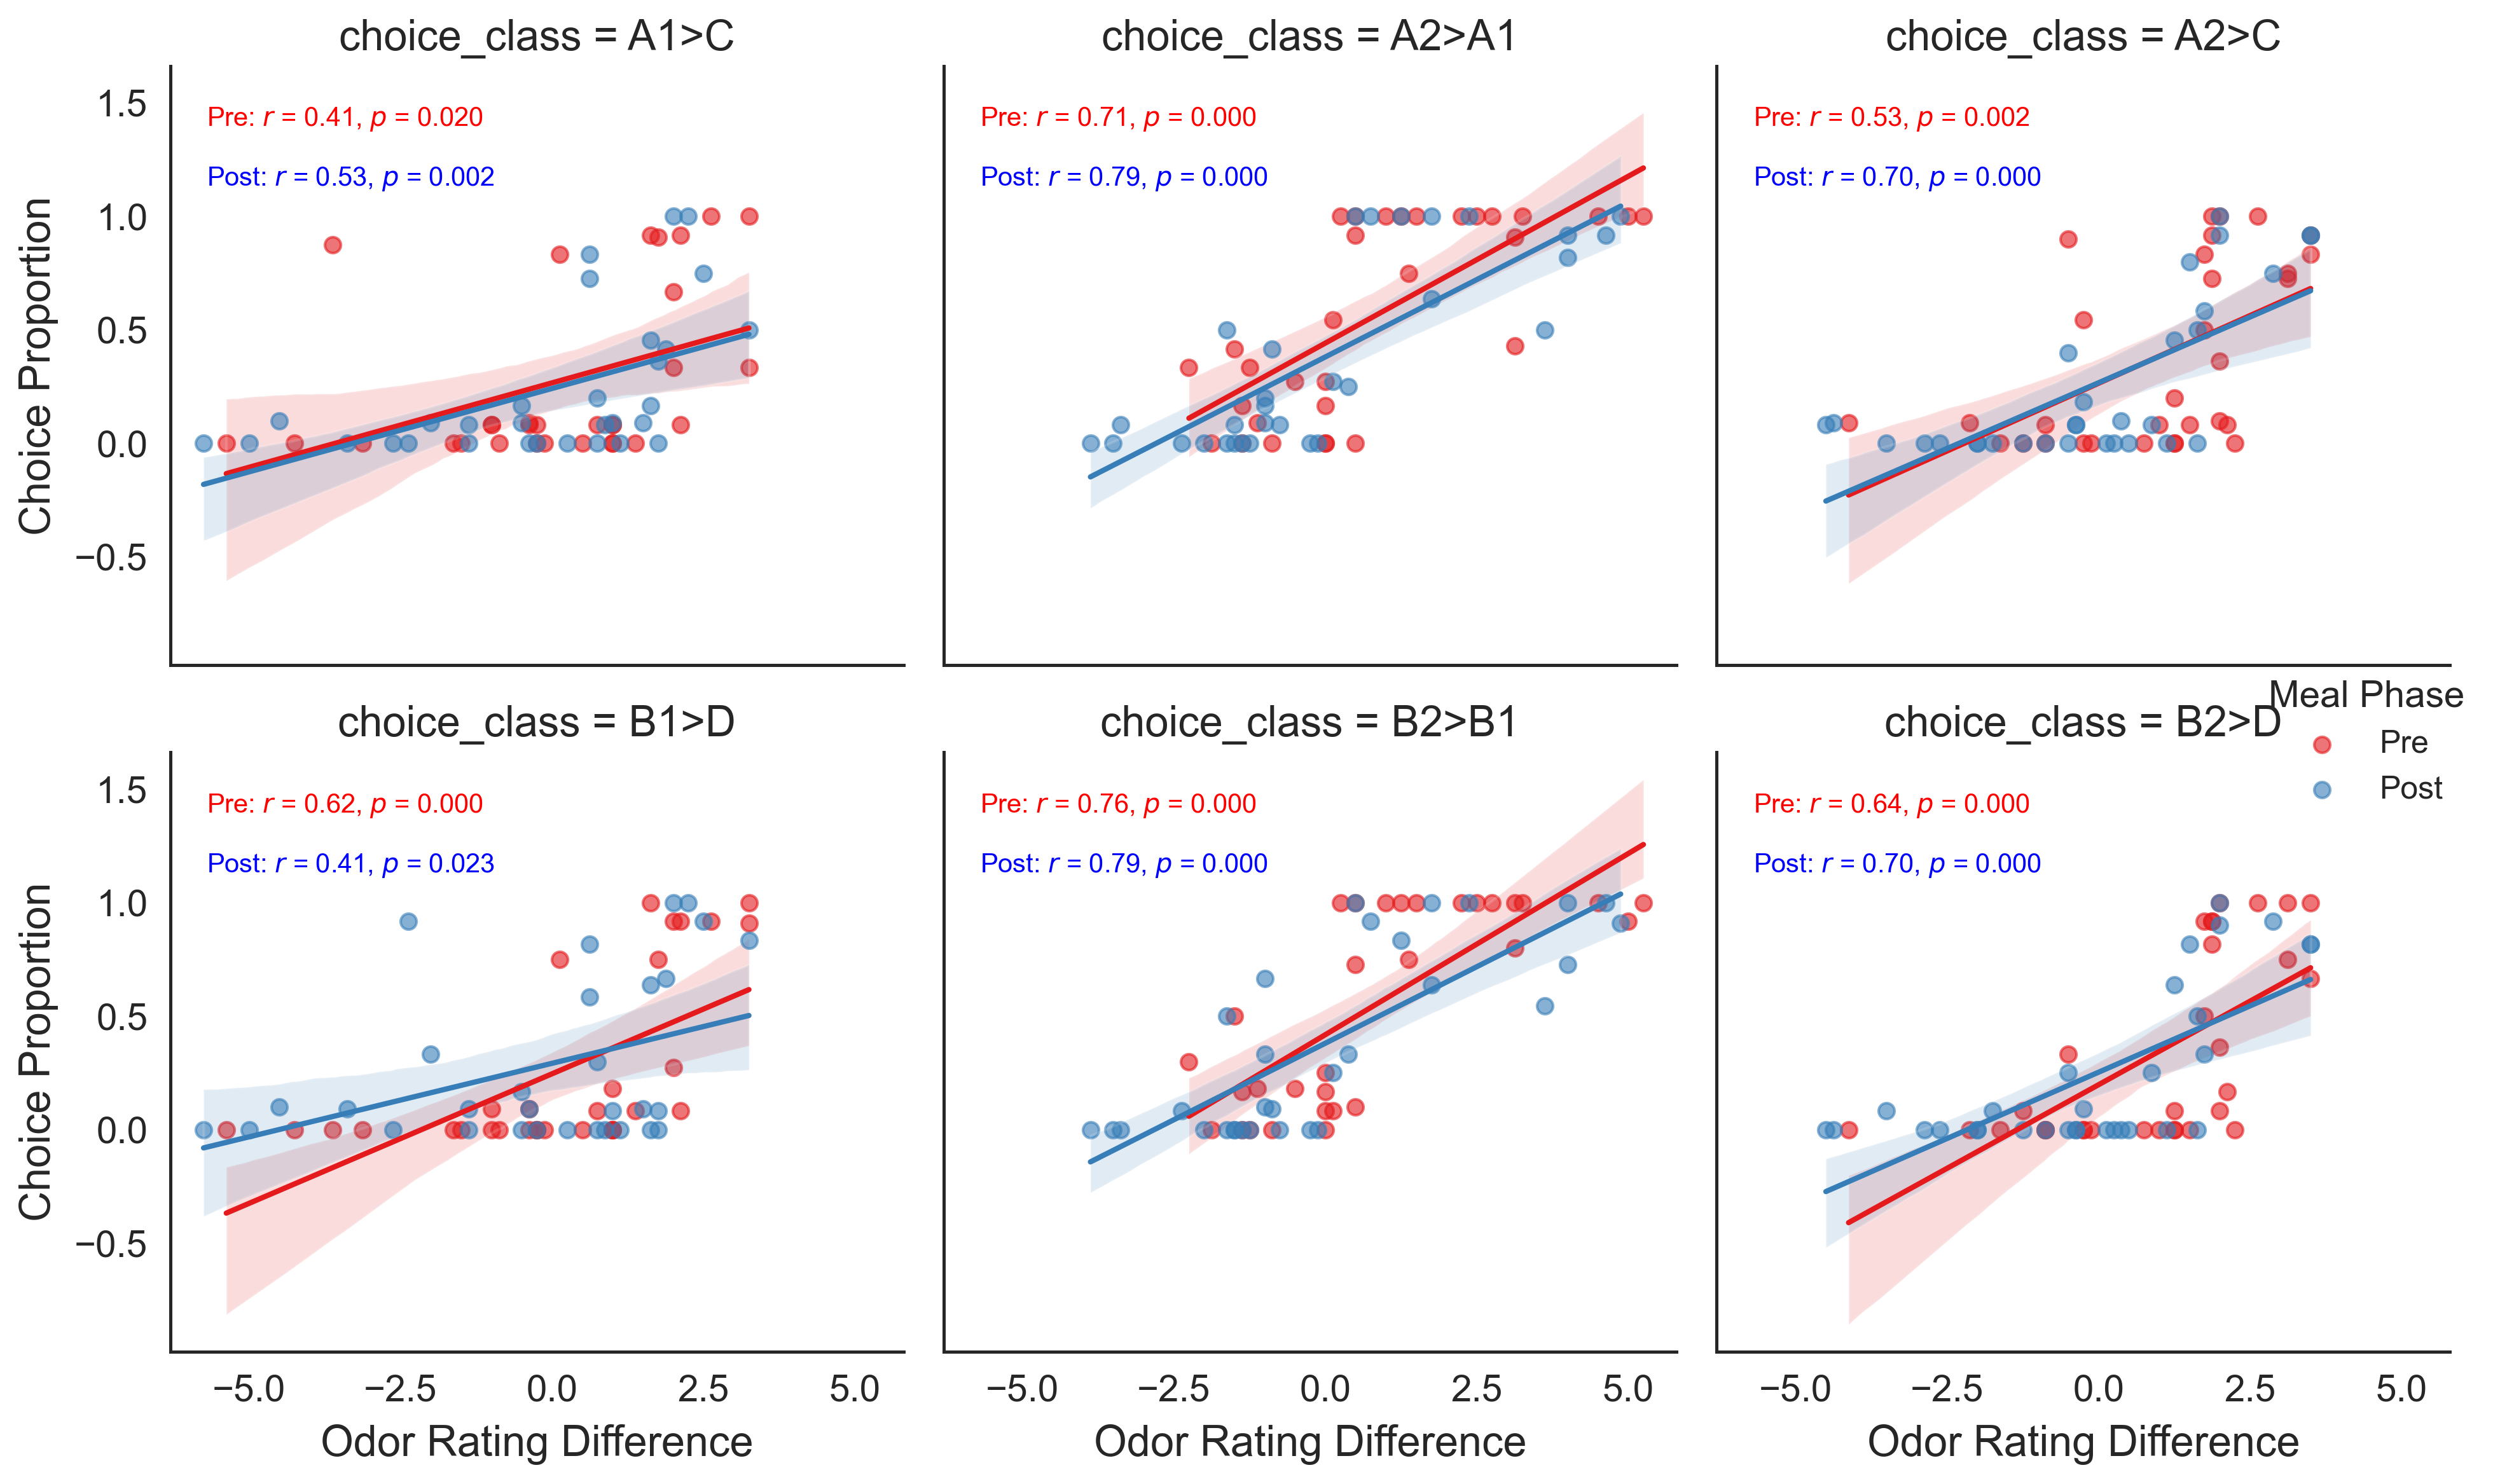

In [30]:
# Drop missing values
plot_df = combined.dropna(subset=['rating_diff', 'choice'])

# Plot: one panel per choice_class, color by meal_phase
g = sns.FacetGrid(
    plot_df,
    col="choice_class", col_wrap=3,
    height=4, sharex=True, sharey=True,
    hue="meal_phase", palette="Set1"
)

g.map_dataframe(
    sns.regplot,
    x="rating_diff", y="choice",
    scatter_kws={'alpha': 0.6},
    line_kws={'linewidth': 2}
)

# Add correlation text for each phase
for ax, name in zip(g.axes.flat, g.col_names):
    subdf = plot_df[plot_df['choice_class'] == name]
    for i, phase in enumerate(["Pre", "Post"]):
        group = subdf[subdf["meal_phase"] == phase]
        if not group.empty:
            r, p = pearsonr(group["rating_diff"], group["choice"])
            ax.text(
                0.05, 0.9 - i * 0.1, f"{phase}: $r$ = {r:.2f}, $p$ = {p:.3f}",
                transform=ax.transAxes, fontsize=10, color=("red" if phase == "Pre" else "blue")
            )

g.set_axis_labels("Odor Rating Difference", "Choice Proportion")
g.add_legend(title="Meal Phase")
plt.tight_layout()
plt.show()


### Summary

Across all choice classes, we observe an overall positive correlation between odor rating differences and choice proportions, both pre- and post-meal. This indicates that participants are more likely to choose odors they rated as more pleasant. 

An observation is that in some cases (e.g., A1>A3), odor rating differences are heavily skewed toward the positive side, while choice proportions are mostly clustered around zero.
